# load the image datast

In [7]:
import pandas as pd
import numpy as np 
import torch
import os

image_df = pd.read_csv(
    "data/processed/image_train_1889.csv"
)

print("Dataset shape : " , image_df.shape)
print(image_df.head())

print("\nLabel distribution:")
print(image_df["2_way_label"].value_counts())

Dataset shape :  (1889, 4)
        id                                        clean_title  \
0   84nojx                                this photo of putin   
1   4x4pit  the name of lenin shines on our victories sovi...   
2  cbvw2jt           i dont think hes the only one alone here   
3   dayn4m  this cat in a costume talking to a goku cosplayer   
4   1ughyb  he survived floor plunge and now walks for cha...   

                    image_path  2_way_label  
0   ../images/train\84nojx.jpg            1  
1   ../images/train\4x4pit.jpg            0  
2  ../images/train\cbvw2jt.jpg            0  
3   ../images/train\dayn4m.jpg            0  
4   ../images/train\1ughyb.jpg            1  

Label distribution:
2_way_label
0    983
1    906
Name: count, dtype: int64


# create the consistent train validation split

In [8]:
from sklearn.model_selection import train_test_split

fusion_train_df , fusion_val_df = train_test_split(
    image_df,
    test_size = 0.20,
    random_state = 42,
    stratify = image_df["2_way_label"]
)

fusion_train_df = fusion_train_df.reset_index(drop=True)
fusion_val_df = fusion_val_df.reset_index(drop=True)

print("Fusion training:", len(fusion_train_df))
print("Fusion validation:", len(fusion_val_df))

Fusion training: 1511
Fusion validation: 378


In [9]:
# load Distilbert model that we finetune earlier

from transformers import AutoTokenizer , AutoModel
import torch 

MODEL_NAME = "distilbert-base-uncased"

text_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

text_model = AutoModel.from_pretrained(MODEL_NAME)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

text_model = text_model.to(device)
text_model.eval()

print("DistilBERT encoder loaded!")
print("Device:", device)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBERT encoder loaded!
Device: cuda


In [10]:
# check the text image Alignement 

print("traning image IDs")
print(fusion_train_df["id"].head().tolist())

print("Training labels")
print(fusion_train_df["2_way_label"].head().tolist())

print("\nTraining titles:")
print(fusion_train_df["clean_title"].head().tolist())

traning image IDs
['cxuhshq', 'cbt2i0p', 'dgt49w', 'dnt6ijh', 'd2dhw8q']
Training labels
[0, 0, 1, 0, 0]

Training titles:
['satsriakal', 'i thought of something with trains too', 'this halloween pumpkin at my dentist', 'wilson mother are impressed', 'httpiimgurcomgxmcwzjpg']


In [11]:
# load saved clip features

import numpy as np
import os

# Load saved CLIP features
image_features = np.load(
    "../features/clip_train_features.npy"
)

image_labels = np.load(
    "../features/clip_train_labels.npy"
)

val_features = np.load(
    "../features/clip_val_features.npy"
)

val_labels = np.load(
    "../features/clip_val_labels.npy"
)

print("CLIP features loaded successfully!")

CLIP features loaded successfully!


In [12]:
# Check feature shapes
print("Training features:", image_features.shape)
print("Training labels:", image_labels.shape)

print("Validation features:", val_features.shape)
print("Validation labels:", val_labels.shape)

Training features: (1511, 512)
Training labels: (1511,)
Validation features: (378, 512)
Validation labels: (378,)


In [13]:
#check the image alignment

print("Training features:", image_features.shape)
print("Training labels:", image_labels.shape)

print("Validation features:", val_features.shape)
print("Validation labels:", val_labels.shape)

# Check that the saved CLIP features match our current split
assert len(image_features) == len(fusion_train_df)
assert len(val_features) == len(fusion_val_df)

assert np.array_equal(
    image_labels,
    fusion_train_df["2_way_label"].to_numpy()
)

assert np.array_equal(
    val_labels,
    fusion_val_df["2_way_label"].to_numpy()
)

print("\nCLIP features and labels are correctly aligned!")

Training features: (1511, 512)
Training labels: (1511,)
Validation features: (378, 512)
Validation labels: (378,)

CLIP features and labels are correctly aligned!


In [14]:
# load distilbert tokenizer and encoder

from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "distilbert-base-uncased"

text_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

text_model = AutoModel.from_pretrained(MODEL_NAME)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

text_model = text_model.to(device)
text_model.eval()

# Freeze pretrained parameters
for param in text_model.parameters():
    param.requires_grad = False

print("DistilBERT encoder loaded successfully!")
print("Device:", device)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBERT encoder loaded successfully!
Device: cuda


# Extract DistilBERT text features

In [15]:
from tqdm.auto import tqdm

def extract_text_features(texts, batch_size=8):

    features_list = []

    text_model.eval()

    for start in tqdm(range(0, len(texts), batch_size)):

        batch_texts = texts.iloc[start:start + batch_size].tolist()

        inputs = text_tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        with torch.no_grad():

            outputs = text_model(**inputs)

            # CLS token representation
            features = outputs.last_hidden_state[:, 0, :]

        features_list.append(features.cpu().numpy())

        del inputs, outputs, features

    return np.concatenate(features_list, axis=0)


text_train_features = extract_text_features(
    fusion_train_df["clean_title"]
)

text_val_features = extract_text_features(
    fusion_val_df["clean_title"]
)

print("Training text features:", text_train_features.shape)
print("Validation text features:", text_val_features.shape)

  0%|          | 0/189 [00:00<?, ?it/s]

  0%|          | 0/48 [00:00<?, ?it/s]

Training text features: (1511, 768)
Validation text features: (378, 768)


In [16]:
# now combine the text and image features

import numpy as np


X_train_fusion = np.concatenate(
    [text_train_features , image_features],
    axis = 1
)

X_val_fusion = np.concatenate(
    [text_val_features , val_features],
    axis = 1 
)

y_train_fusion = fusion_train_df["2_way_label"].to_numpy()
y_val_fusion = fusion_val_df["2_way_label"].to_numpy()

print("Combined training shape:", X_train_fusion.shape)
print("Combined validation shape:", X_val_fusion.shape)

Combined training shape: (1511, 1280)
Combined validation shape: (378, 1280)


# now train the multimodal classifier

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

fusion_classifier = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

fusion_classifier.fit(
    X_train_fusion,
    y_train_fusion
)

print("Multimodal classifier trained successfully!")

Multimodal classifier trained successfully!


In [14]:
# evalute the multimodal

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

fusion_predictions = fusion_classifier.predict(X_val_fusion)

fusion_accuracy = accuracy_score(
    y_val_fusion, fusion_predictions
)

fusion_precision = precision_score(
    y_val_fusion, fusion_predictions
)

fusion_recall = recall_score(
    y_val_fusion, fusion_predictions
)

fusion_f1 = f1_score(
    y_val_fusion, fusion_predictions
)

print("MULTIMODAL FUSION RESULTS")
print("-------------------------")
print("Accuracy:", round(fusion_accuracy, 4))
print("Precision:", round(fusion_precision, 4))
print("Recall:", round(fusion_recall, 4))
print("F1 Score:", round(fusion_f1, 4))

print("\nClassification Report:")
print(classification_report(y_val_fusion, fusion_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_fusion, fusion_predictions))

MULTIMODAL FUSION RESULTS
-------------------------
Accuracy: 0.8466
Precision: 0.8555
Recall: 0.8177
F1 Score: 0.8362

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.87      0.86       197
           1       0.86      0.82      0.84       181

    accuracy                           0.85       378
   macro avg       0.85      0.85      0.85       378
weighted avg       0.85      0.85      0.85       378


Confusion Matrix:
[[172  25]
 [ 33 148]]


In [15]:
# comapre all three models 

# Text-only classifier
text_classifier = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

text_classifier.fit(
    text_train_features,
    y_train_fusion
)

text_predictions = text_classifier.predict(
    text_val_features
)

# Image-only classifier
image_classifier = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

image_classifier.fit(
    image_features,
    y_train_fusion
)

image_predictions = image_classifier.predict(
    val_features
)

# Comparison
comparison = pd.DataFrame({
    "Model": [
        "DistilBERT Text Features",
        "CLIP Image Features",
        "Multimodal Fusion"
    ],
    "Accuracy": [
        accuracy_score(y_val_fusion, text_predictions),
        accuracy_score(y_val_fusion, image_predictions),
        fusion_accuracy
    ],
    "F1 Score": [
        f1_score(y_val_fusion, text_predictions),
        f1_score(y_val_fusion, image_predictions),
        fusion_f1
    ]
})

display(comparison)

,Model,Accuracy,F1 Score
0,DistilBERT Text Features,0.748677,0.748011
1,CLIP Image Features,0.772487,0.754286
2,Multimodal Fusion,0.846561,0.836158


In [16]:
import json
import os

os.makedirs("../results", exist_ok=True)

fusion_results = {
    "dataset": "Fakeddit",
    "validation_samples": 378,
    "models": {
        "DistilBERT_Text": {
            "accuracy": 0.748677,
            "f1_score": 0.748011
        },
        "CLIP_Image": {
            "accuracy": 0.772487,
            "f1_score": 0.754286
        },
        "Multimodal_Fusion": {
            "accuracy": 0.846561,
            "f1_score": 0.836158
        }
    }
}

with open("../results/multimodal_results.json", "w") as f:
    json.dump(fusion_results, f, indent=4)

print("Multimodal results saved successfully!")

Multimodal results saved successfully!


In [17]:
#saved the fusion classifier
import joblib

joblib.dump(
    fusion_classifier,
    "../models/multimodal_fusion_classifier.pkl"
)

print("Fusion classifier saved successfully!")

Fusion classifier saved successfully!


In [18]:
np.save("../features/distilbert_train_features.npy", text_train_features)
np.save("../features/distilbert_val_features.npy", text_val_features)

print("DistilBERT text features saved successfully!")

DistilBERT text features saved successfully!


# Source Feature Ablation

In [19]:
from sklearn.pipeline import Pipeline 
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score , f1_score
import pandas as pd
import numpy as np 

# text + image baseline 

X_train_ti = np.concatenate(
    [text_train_features , image_features] , axis = 1
)

X_val_ti = np.concatenate(
    [text_val_features , val_features] , axis = 1
)

# source feature group 

domain_cols = [
    "domain_Image Hosting",
    "domain_News Publisher",
    "domain_Unknown",
    "domain_other"
]

indicator_cols = [
    "is_missing_domain",
    "is_image_host",
    "is_known_publisher"
]

all_source_cols = domain_cols + indicator_cols + [
    "log_domain_frequency"
]

print("Text + Image:", X_train_ti.shape)
print("Domain columns:", len(domain_cols))
print("Source indicators:", len(indicator_cols))
print("All source columns:", len(all_source_cols))


Text + Image: (1511, 1280)
Domain columns: 4
Source indicators: 3
All source columns: 8


In [20]:
# create the labels 

y_train_full = fusion_train_df["2_way_label"].to_numpy()
y_val_full = fusion_val_df["2_way_label"].to_numpy()

print("Training labels:", y_train_full.shape)
print("Validation labels:", y_val_full.shape)

Training labels: (1511,)
Validation labels: (378,)


In [26]:
# extra
# rebuild the source data 


import pandas as pd
import numpy as np

# Load original training data
train_df = pd.read_csv("data/processed/train_20k.csv")

# Categorize domains
def categorize_domain(domain):
    if pd.isna(domain):
        return "Unknown"

    domain = str(domain).lower()

    image_domains = [
        "i.redd.it", "i.imgur.com", "imgur.com",
        "i.reddituploads.com", "v.redd.it"
    ]

    news_domains = [
        "reuters.com", "theguardian.com", "bbc.com",
        "bbc.co.uk", "washingtonpost.com", "cnn.com",
        "nytimes.com", "cbc.ca", "independent.co.uk",
        "foxnews.com"
    ]

    if domain in image_domains:
        return "Image Hosting"
    elif domain in news_domains:
        return "News Publisher"
    return "other"

train_df["domain_category"] = train_df["domain"].apply(
    categorize_domain
)

# Source indicators
train_df["is_missing_domain"] = train_df["domain"].isna().astype(int)

train_df["is_image_host"] = (
    train_df["domain_category"] == "Image Hosting"
).astype(int)

train_df["is_known_publisher"] = (
    train_df["domain_category"] == "News Publisher"
).astype(int)

# Domain frequency
domain_counts = train_df["domain"].value_counts()

train_df["log_domain_frequency"] = np.log1p(
    train_df["domain"].map(domain_counts).fillna(0)
)

# Match the 1889 image records
image_df = pd.read_csv("data/processed/image_train_1889.csv")

train_df["id"] = train_df["id"].astype(str)
image_df["id"] = image_df["id"].astype(str)

source_subset = (
    train_df.set_index("id")
    .loc[image_df["id"]]
    .reset_index()
)

# One-hot encoding
domain_encoded = pd.get_dummies(
    source_subset["domain_category"],
    prefix="domain",
    dtype=int
)

source_features_subset = pd.concat(
    [
        domain_encoded.reset_index(drop=True),
        source_subset[
            [
                "is_missing_domain",
                "is_image_host",
                "is_known_publisher",
                "log_domain_frequency"
            ]
        ].reset_index(drop=True)
    ],
    axis=1
)

print("Source feature shape:", source_features_subset.shape)
print("IDs aligned:", np.array_equal(
    source_subset["id"].to_numpy(),
    image_df["id"].to_numpy()
))


Source feature shape: (1889, 8)
IDs aligned: True


In [27]:
# extra
# Recreate source features


# Recreate the same train-validation split
from sklearn.model_selection import train_test_split
import numpy as np

indices = np.arange(len(image_df))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=image_df["2_way_label"]
)

# Recreate source feature arrays
source_train_features = source_features_subset.iloc[
    train_idx
].to_numpy(dtype=np.float32)

source_val_features = source_features_subset.iloc[
    val_idx
].to_numpy(dtype=np.float32)

print("Source training:", source_train_features.shape)
print("Source validation:", source_val_features.shape)


Source training: (1511, 8)
Source validation: (378, 8)


In [29]:
# extra 
# Recreate complete Text + Image + Source matrices

X_train_full = np.concatenate(
    [
        text_train_features,
        image_features,
        source_train_features
    ],
    axis=1
)

X_val_full = np.concatenate(
    [
        text_val_features,
        val_features,
        source_val_features
    ],
    axis=1
)

# Recreate labels
y_train_full = image_df.iloc[train_idx]["2_way_label"].to_numpy()
y_val_full = image_df.iloc[val_idx]["2_way_label"].to_numpy()

print("Training:", X_train_full.shape)
print("Validation:", X_val_full.shape)


Training: (1511, 1288)
Validation: (378, 1288)


In [30]:
# Train and compare the configurations
def evaluate_model(X_train, X_val, y_train, y_val):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_val)

    return (
        accuracy_score(y_val, predictions),
        f1_score(y_val, predictions)
    )

experiments = {}

# 1. Text + Image
experiments["Text + Image"] = evaluate_model(
    X_train_ti, X_val_ti,
    y_train_full, y_val_full
)

# 2. Text + Image + Domain Category
experiments["TI + Domain Category"] = evaluate_model(
    np.concatenate([
        X_train_ti,
        source_train_features[:, :4]
    ], axis=1),
    np.concatenate([
        X_val_ti,
        source_val_features[:, :4]
    ], axis=1),
    y_train_full, y_val_full
)

# 3. Text + Image + Source Indicators
experiments["TI + Source Indicators"] = evaluate_model(
    np.concatenate([
        X_train_ti,
        source_train_features[:, 4:7]
    ], axis=1),
    np.concatenate([
        X_val_ti,
        source_val_features[:, 4:7]
    ], axis=1),
    y_train_full, y_val_full
)

# 4. Text + Image + All Source Features
experiments["TI + All Source Features"] = evaluate_model(
    X_train_full, X_val_full,
    y_train_full, y_val_full
)

# Display comparison
ablation_results = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": round(metrics[0] * 100, 2),
        "F1 Score": round(metrics[1] * 100, 2)
    }
    for name, metrics in experiments.items()
])

print(ablation_results.to_string(index=False))


                   Model  Accuracy  F1 Score
            Text + Image     84.66     83.62
    TI + Domain Category     84.92     83.85
  TI + Source Indicators     84.66     83.62
TI + All Source Features     84.66     83.62


In [31]:
# save the abilation result 


import json
import os

ablation_data = {
    "Text + Image": {
        "accuracy": 84.66,
        "f1_score": 83.62
    },
    "TI + Domain Category": {
        "accuracy": 84.92,
        "f1_score": 83.85
    },
    "TI + Source Indicators": {
        "accuracy": 84.66,
        "f1_score": 83.62
    },
    "TI + All Source Features": {
        "accuracy": 84.66,
        "f1_score": 83.62
    }
}

os.makedirs("../results", exist_ok=True)

with open("../results/source_ablation_results.json", "w") as f:
    json.dump(ablation_data, f, indent=4)

print("Source ablation results saved successfully!")


Source ablation results saved successfully!


In [32]:
# Recalculate domain frequency without leakage 


# Calculate domain frequency using training records only

train_domains = source_subset.iloc[train_idx]["domain"]

# Learn frequency counts from training data
domain_counts_train = train_domains.value_counts()

# Apply training-derived counts to training and validation
source_train_df = source_subset.iloc[train_idx].copy()
source_val_df = source_subset.iloc[val_idx].copy()

source_train_df["log_domain_frequency"] = np.log1p(
    source_train_df["domain"].map(domain_counts_train).fillna(0)
)

source_val_df["log_domain_frequency"] = np.log1p(
    source_val_df["domain"].map(domain_counts_train).fillna(0)
)

print("Training records:", len(source_train_df))
print("Validation records:", len(source_val_df))

print("\nTraining domain frequency:")
print(source_train_df["log_domain_frequency"].describe())

print("\nValidation domain frequency:")
print(source_val_df["log_domain_frequency"].describe())


Training records: 1511
Validation records: 378

Training domain frequency:
count    1511.000000
mean        3.083315
std         2.638241
min         0.000000
25%         0.000000
50%         2.397895
75%         6.095825
max         6.095825
Name: log_domain_frequency, dtype: float64

Validation domain frequency:
count    378.000000
mean       3.123225
std        2.745497
min        0.000000
25%        0.000000
50%        4.356709
75%        6.095825
max        6.095825
Name: log_domain_frequency, dtype: float64


In [33]:
# NOw we rebuild corrected source features


# Create corrected domain category features
domain_train_encoded = pd.get_dummies(
    source_train_df["domain_category"],
    prefix="domain",
    dtype=int
)

domain_val_encoded = pd.get_dummies(
    source_val_df["domain_category"],
    prefix="domain",
    dtype=int
)

# Ensure identical columns in train and validation
domain_val_encoded = domain_val_encoded.reindex(
    columns=domain_train_encoded.columns,
    fill_value=0
)

# Combine domain categories and source indicators
source_train_corrected = pd.concat(
    [
        domain_train_encoded.reset_index(drop=True),
        source_train_df[
            ["is_missing_domain", "is_image_host", "is_known_publisher"]
        ].reset_index(drop=True),
        source_train_df[
            ["log_domain_frequency"]
        ].reset_index(drop=True)
    ],
    axis=1
)

source_val_corrected = pd.concat(
    [
        domain_val_encoded.reset_index(drop=True),
        source_val_df[
            ["is_missing_domain", "is_image_host", "is_known_publisher"]
        ].reset_index(drop=True),
        source_val_df[
            ["log_domain_frequency"]
        ].reset_index(drop=True)
    ],
    axis=1
)

print("Corrected training source:", source_train_corrected.shape)
print("Corrected validation source:", source_val_corrected.shape)
print("Columns match:", list(source_train_corrected.columns) ==
      list(source_val_corrected.columns))



Corrected training source: (1511, 8)
Corrected validation source: (378, 8)
Columns match: True


In [34]:
# Combine corrected source features with text and image 


# Convert corrected source features to NumPy
source_train_corrected_np = source_train_corrected.to_numpy(
    dtype=np.float32
)

source_val_corrected_np = source_val_corrected.to_numpy(
    dtype=np.float32
)

# Combine Text + Image + Corrected Source
X_train_corrected = np.concatenate(
    [
        text_train_features,
        image_features,
        source_train_corrected_np
    ],
    axis=1
)

X_val_corrected = np.concatenate(
    [
        text_val_features,
        val_features,
        source_val_corrected_np
    ],
    axis=1
)

print("Corrected training shape:", X_train_corrected.shape)
print("Corrected validation shape:", X_val_corrected.shape)


Corrected training shape: (1511, 1288)
Corrected validation shape: (378, 1288)


In [36]:
# now train the corrected model 


from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

corrected_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

corrected_model.fit(X_train_corrected, y_train_full)

corrected_predictions = corrected_model.predict(X_val_corrected)

corrected_accuracy = accuracy_score(
    y_val_full, corrected_predictions
)
corrected_precision = precision_score(
    y_val_full, corrected_predictions
)
corrected_recall = recall_score(
    y_val_full, corrected_predictions
)
corrected_f1 = f1_score(
    y_val_full, corrected_predictions
)

print("Corrected Model Performance")
print("Accuracy :", round(corrected_accuracy * 100, 2), "%")
print("Precision:", round(corrected_precision, 4))
print("Recall   :", round(corrected_recall, 4))
print("F1 Score :", round(corrected_f1, 4))


Corrected Model Performance
Accuracy : 84.66 %
Precision: 0.8555
Recall   : 0.8177
F1 Score : 0.8362


In [38]:
# save the corrected model 


import joblib
import json

joblib.dump(
    corrected_model,
    "../models/corrected_text_image_source_model.pkl"
)

corrected_results = {
    "model": "Corrected Text + Image + Source",
    "accuracy": float(corrected_accuracy),
    "precision": float(corrected_precision),
    "recall": float(corrected_recall),
    "f1_score": float(corrected_f1),
    "validation_samples": len(y_val_full)
}

with open("../results/corrected_source_fusion_results.json", "w") as f:
    json.dump(corrected_results, f, indent=4)

print("Corrected model saved successfully!")
print("Corrected results saved successfully!")


Corrected model saved successfully!
Corrected results saved successfully!


In [39]:
# prepare domain category features

# Select only the 4 domain category columns
domain_cols = [
    "domain_Image Hosting",
    "domain_News Publisher",
    "domain_Unknown",
    "domain_other"
]

# Extract corrected training and validation features
domain_train_corrected = domain_train_encoded[
    domain_cols
].to_numpy(dtype=np.float32)

domain_val_corrected = domain_val_encoded[
    domain_cols
].to_numpy(dtype=np.float32)

print("Domain training:", domain_train_corrected.shape)
print("Domain validation:", domain_val_corrected.shape)

Domain training: (1511, 4)
Domain validation: (378, 4)


In [40]:
# Train the corrected Domain Category model
# Now we'll combine:
#  DistilBERT text features: 768
#  CLIP image features: 512
#  Domain category features: 4
# Total: 1,284 features per news record


# Combine Text + Image + Domain Category

X_train_domain = np.concatenate(
    [
        text_train_features,
        image_features,
        domain_train_corrected
    ],
    axis=1
)

X_val_domain = np.concatenate(
    [
        text_val_features,
        val_features,
        domain_val_corrected
    ],
    axis=1
)

print("Training shape:", X_train_domain.shape)
print("Validation shape:", X_val_domain.shape)


Training shape: (1511, 1284)
Validation shape: (378, 1284)


In [41]:
 # train and evalute 

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

domain_model = Pipeline([
    ("scaler" , StandardScaler()),
    ("classifier" , LogisticRegression(
        max_iter = 2000,
        random_state = 42
    ))
])

domain_model.fit(X_train_domain, y_train_full)

domain_predictions = domain_model.predict(X_val_domain)

domain_accuracy = accuracy_score(
    y_val_full, domain_predictions
)
domain_precision = precision_score(
    y_val_full, domain_predictions
)
domain_recall = recall_score(
    y_val_full, domain_predictions
)
domain_f1 = f1_score(
    y_val_full, domain_predictions
)

print("Corrected Domain Category Model")
print("Accuracy :", round(domain_accuracy * 100, 2), "%")
print("Precision:", round(domain_precision, 4))
print("Recall   :", round(domain_recall, 4))
print("F1 Score :", round(domain_f1, 4))


Corrected Domain Category Model
Accuracy : 84.92 %
Precision: 0.8605
Recall   : 0.8177
F1 Score : 0.8385


In [42]:

import joblib
import json

# Save trained model
joblib.dump(
    domain_model,
    "../models/corrected_text_image_domain_model.pkl"
)

# Save results
domain_results = {
    "model": "Text + Image + Domain Category",
    "accuracy": float(domain_accuracy),
    "precision": float(domain_precision),
    "recall": float(domain_recall),
    "f1_score": float(domain_f1),
    "validation_samples": len(y_val_full)
}

with open(
    "../results/corrected_domain_model_results.json", "w"
) as f:
    json.dump(domain_results, f, indent=4)

print("Corrected domain model saved successfully!")
print("Domain model results saved successfully!")



Corrected domain model saved successfully!
Domain model results saved successfully!


In [29]:
# now test the model on unseen data using the test_10k.csv

import pandas as pd 
import numpy as np 

# Load the dataset 

test_df = pd.read_csv("data/processed/test_10k.csv")
print("Test dataset shape:", test_df.shape)

print("\nAvailable columns:")
print(test_df.columns.tolist())

print("\nLabel distribution:")
print(test_df["2_way_label"].value_counts())

print("\nMissing values:")
print(test_df[["clean_title", "image_url", "domain"]].isna().sum())


Test dataset shape: (10000, 16)

Available columns:
['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label']

Label distribution:
2_way_label
1    5000
0    5000
Name: count, dtype: int64

Missing values:
clean_title       0
image_url        31
domain         2488
dtype: int64


In [45]:
# now check the data sepration 


# Load training dataset
train_check = pd.read_csv("data/processed/train_20k.csv")

# Convert IDs to strings
test_ids = set(test_df["id"].astype(str))
train_ids = set(train_check["id"].astype(str))

# Check overlap
overlap_ids = test_ids.intersection(train_ids)

print("Test records:", len(test_ids))
print("Training records:", len(train_ids))
print("Overlapping IDs:", len(overlap_ids))

# Check image URL availability
print("\nImage URL availability:")
print("Available URLs:", test_df["image_url"].notna().sum())
print("Missing URLs:", test_df["image_url"].isna().sum())

# Check domain availability
print("\nDomain availability:")
print("Available domains:", test_df["domain"].notna().sum())
print("Missing domains:", test_df["domain"].isna().sum())


Test records: 10000
Training records: 20000
Overlapping IDs: 0

Image URL availability:
Available URLs: 9969
Missing URLs: 31

Domain availability:
Available domains: 7512
Missing domains: 2488


In [48]:
 #prepare the image dataset 

import os

# create the seperate folder

test_image_dir = "../images/test_images"
os.makedirs(text_image_dir , exist_ok = True)

# Now select records image urls

test_image_df = test_df[
    test_df["image_url"].notna()
].copy()

print("Test records with image URLs:", len(test_image_df))
print("Images will be stored in:", test_image_dir)

# Save image download list
test_image_df[
    ["id", "image_url", "clean_title", "2_way_label", "domain"]
].to_csv(
    "../images/test_image_download_list.csv",
    index=False
)


Test records with image URLs: 9969
Images will be stored in: ../images/test_images


In [49]:
# now verify the download list 

print("Test image records:", len(test_image_df))

print(
    test_image_df[
        ["id", "image_url", "clean_title", "2_way_label", "domain"]
    ].head()
)

Test image records: 9969
        id                                          image_url  \
0   bfp6uh  https://preview.redd.it/pa4odwiqkmt21.jpg?widt...   
1   bt3al6  https://preview.redd.it/hyco5d9t4h031.jpg?widt...   
2  c88ctxo                     http://i.imgur.com/jBXVoMt.jpg   
3  crmnt15                     http://i.imgur.com/AMonyWm.jpg   
4  c7nhge8                       http://i.imgur.com/2yb8n.jpg   

                                         clean_title  2_way_label     domain  
0  this toilet in the netherlands asks you to sep...            1  i.redd.it  
1                                        nice buwait            0  i.redd.it  
2                                bollywood star wars            0        NaN  
3             archer really pulls of those stockings            0        NaN  
4                             yes i can catch em all            0        NaN  


In [50]:
# now downlaod the test image


import requests
from PIL import Image
from io import BytesIO
from tqdm.auto import tqdm
import os
import pandas as pd

successful_images = []
failed_images = []

for _, row in tqdm(test_image_df.iterrows(), total=len(test_image_df)):

    image_id = str(row["id"])
    image_url = row["image_url"]

    image_path = os.path.join(
        test_image_dir,
        image_id + ".jpg"
    )

    try:
        response = requests.get(
            image_url,
            timeout=10,
            headers={"User-Agent": "Mozilla/5.0"}
        )

        response.raise_for_status()

        image = Image.open(
            BytesIO(response.content)
        ).convert("RGB")

        image.save(image_path, "JPEG", quality=95)

        successful_images.append({
            "id": image_id,
            "image_path": image_path
        })

    except Exception as e:
        failed_images.append({
            "id": image_id,
            "image_url": image_url,
            "error": str(e)
        })

# Save download records
pd.DataFrame(successful_images).to_csv(
    "../images/test_successful_images.csv",
    index=False
)

pd.DataFrame(failed_images).to_csv(
    "../images/test_failed_images.csv",
    index=False
)

print("Successful downloads:", len(successful_images))
print("Failed downloads:", len(failed_images))


  0%|          | 0/9969 [00:00<?, ?it/s]

C:\Users\lenovo\anaconda3\envs\fake_news_pro\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Successful downloads: 0
Failed downloads: 9969


In [52]:
# now identify the download error

# Inspect first 20 failed downloads

for item in failed_images[:20]:
    print("ID" , item["id"])
    print("error" , item["error"])
    print("-" * 50)

#count different error types

error_df = pd.DataFrame(failed_images)

print("\n Error summary : ")
print(
    error_df["error"].value_counts().head(15)
)    

ID bfp6uh
error [Errno 2] No such file or directory: '../images/test_images\\bfp6uh.jpg'
--------------------------------------------------
ID bt3al6
error [Errno 2] No such file or directory: '../images/test_images\\bt3al6.jpg'
--------------------------------------------------
ID c88ctxo
error [Errno 2] No such file or directory: '../images/test_images\\c88ctxo.jpg'
--------------------------------------------------
ID crmnt15
error [Errno 2] No such file or directory: '../images/test_images\\crmnt15.jpg'
--------------------------------------------------
ID c7nhge8
error [Errno 2] No such file or directory: '../images/test_images\\c7nhge8.jpg'
--------------------------------------------------
ID 3dsrt5
error [Errno 2] No such file or directory: '../images/test_images\\3dsrt5.jpg'
--------------------------------------------------
ID daygn7i
error [Errno 2] No such file or directory: '../images/test_images\\daygn7i.jpg'
--------------------------------------------------
ID ctpbu9
er

In [53]:
# now check one image url manually 


import requests

sample_url = test_image_df["image_url"].iloc[0]

try:
    response = requests.get(
        sample_url,
        timeout=20,
        headers={
            "User-Agent": "Mozilla/5.0"
        }
    )

    print("Status code:", response.status_code)
    print("Content type:", response.headers.get("Content-Type"))
    print("Response size:", len(response.content))

except Exception as e:
    print("Error:", repr(e))


Status code: 200
Content type: image/jpeg
Response size: 13974


In [54]:
# now due the failed imges we fix the folder path 


import os

test_image_dir = os.path.abspath("../images/test_images")

os.makedirs(test_image_dir, exist_ok=True)

print("Folder path:", test_image_dir)
print("Folder exists:", os.path.isdir(test_image_dir))


Folder path: C:\Users\lenovo\images\test_images
Folder exists: True


In [55]:

import requests
from PIL import Image
from io import BytesIO
from tqdm.auto import tqdm
import os
import pandas as pd

successful_images = []
failed_images = []

os.makedirs(test_image_dir, exist_ok=True)

session = requests.Session()
session.headers.update({
    "User-Agent": "Mozilla/5.0"
})

for _, row in tqdm(test_image_df.iterrows(),
                   total=len(test_image_df)):

    image_id = str(row["id"])
    image_url = row["image_url"]

    image_path = os.path.join(
        test_image_dir,
        f"{image_id}.jpg"
    )

    try:
        response = session.get(
            image_url,
            timeout=20
        )
        response.raise_for_status()

        image = Image.open(
            BytesIO(response.content)
        ).convert("RGB")

        image.save(image_path, format="JPEG")

        successful_images.append({
            "id": image_id,
            "image_path": image_path
        })

    except Exception as e:
        failed_images.append({
            "id": image_id,
            "image_url": image_url,
            "error": str(e)
        })

pd.DataFrame(successful_images).to_csv(
    "../images/test_successful_images.csv",
    index=False
)

pd.DataFrame(failed_images).to_csv(
    "../images/test_failed_images.csv",
    index=False
)

print("Successful downloads:", len(successful_images))
print("Failed downloads:", len(failed_images))


  0%|          | 0/9969 [00:00<?, ?it/s]

C:\Users\lenovo\anaconda3\envs\fake_news_pro\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Successful downloads: 9443
Failed downloads: 526


In [30]:
# now we will prepare the test image dataset 


# Load successfully downloaded image records
successful_test_df = pd.read_csv(
    "../images/test_successful_images.csv"
)

# Match with original test dataset
test_df["id"] = test_df["id"].astype(str)
successful_test_df["id"] = successful_test_df["id"].astype(str)

test_image_dataset = successful_test_df.merge(
    test_df[["id", "clean_title", "2_way_label", "domain"]],
    on="id",
    how="inner"
)

# Verify image files
test_image_dataset["image_exists"] = (
    test_image_dataset["image_path"].apply(os.path.isfile)
)

test_image_dataset = test_image_dataset[
    test_image_dataset["image_exists"]
].copy()

print("Final test image dataset:", test_image_dataset.shape)

print("\nLabel distribution:")
print(test_image_dataset["2_way_label"].value_counts())

print("\nAll image files exist:",
      test_image_dataset["image_exists"].all())


Final test image dataset: (9443, 6)

Label distribution:
2_way_label
0    4789
1    4654
Name: count, dtype: int64

All image files exist: True


In [57]:
# now we will extract Clip image features


import torch
import numpy as np
from PIL import Image
from transformers import CLIPModel, CLIPProcessor
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load pretrained CLIP
clip_model = CLIPModel.from_pretrained(
    "openai/clip-vit-base-patch32"
).to(device)

clip_processor = CLIPProcessor.from_pretrained(
    "openai/clip-vit-base-patch32"
)

clip_model.eval()

for param in clip_model.parameters():
    param.requires_grad = False

# Test image dataset
class TestImageDataset(Dataset):
    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        processed = clip_processor(
            images=image,
            return_tensors="pt"
        )

        return processed["pixel_values"].squeeze(0)

test_image_loader = DataLoader(
    TestImageDataset(test_image_dataset),
    batch_size=8,
    shuffle=False,
    num_workers=0
)

# Extract CLIP image embeddings
test_image_features = []

with torch.no_grad():
    for batch in tqdm(test_image_loader):
        pixel_values = batch.to(device)

        vision_output = clip_model.vision_model(
            pixel_values=pixel_values
        )

        features = clip_model.visual_projection(
            vision_output.pooler_output
        )

        features = features / features.norm(
            dim=-1, keepdim=True
        )

        test_image_features.append(
            features.cpu().numpy()
        )

test_image_features = np.concatenate(
    test_image_features,
    axis=0
)

print("Test CLIP features:", test_image_features.shape)


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  0%|          | 0/1181 [00:00<?, ?it/s]

Test CLIP features: (9443, 512)


In [58]:
# now save the extarcted features
np.save(
    "../features/clip_test_features.npy",
    test_image_features
)

print("Test CLIP features saved successfully!")

Test CLIP features saved successfully!


In [59]:
# now create extracted distilbert features


from transformers import AutoTokenizer, AutoModel
from torch.utils.data import Dataset, DataLoader
import torch
import numpy as np
from tqdm.auto import tqdm

# Load DistilBERT
tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-uncased"
)

text_model = AutoModel.from_pretrained(
    "distilbert-base-uncased"
).to(device)

text_model.eval()

for param in text_model.parameters():
    param.requires_grad = False

# Text dataset
class TestTextDataset(Dataset):
    def __init__(self, texts):
        self.texts = texts.astype(str).tolist()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoded = tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=128,
            return_tensors="pt"
        )

        return {
            "input_ids": encoded["input_ids"].squeeze(0),
            "attention_mask": encoded["attention_mask"].squeeze(0)
        }

test_text_loader = DataLoader(
    TestTextDataset(test_image_dataset["clean_title"]),
    batch_size=8,
    shuffle=False,
    num_workers=0
)

# Extract text features
test_text_features = []

with torch.no_grad():
    for batch in tqdm(test_text_loader):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        outputs = text_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        cls_features = outputs.last_hidden_state[:, 0, :]

        test_text_features.append(
            cls_features.cpu().numpy()
        )

test_text_features = np.concatenate(
    test_text_features,
    axis=0
)

print("Test DistilBERT features:", test_text_features.shape)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  0%|          | 0/1181 [00:00<?, ?it/s]

Test DistilBERT features: (9443, 768)


In [60]:
# now save

np.save(
    "../features/distilbert_test_features.npy",
    test_text_features
)

print("Test DistilBERT features saved successfully!")


Test DistilBERT features saved successfully!


In [61]:
# Create test domain-category features


# Prepare test domain categories

def categorize_test_domain(domain):
    if pd.isna(domain):
        return "Unknown"

    domain = str(domain).lower()

    image_domains = [
        "i.redd.it",
        "i.imgur.com",
        "imgur.com",
        "i.reddituploads.com",
        "v.redd.it"
    ]

    news_domains = [
        "reuters.com",
        "theguardian.com",
        "bbc.com",
        "bbc.co.uk",
        "washingtonpost.com",
        "cnn.com",
        "nytimes.com",
        "cbc.ca",
        "independent.co.uk",
        "foxnews.com"
    ]

    if domain in image_domains:
        return "Image Hosting"
    elif domain in news_domains:
        return "News Publisher"
    return "other"


test_image_dataset["domain_category"] = (
    test_image_dataset["domain"].apply(categorize_test_domain)
)

# One-hot encode using the same training categories
test_domain_encoded = pd.get_dummies(
    test_image_dataset["domain_category"],
    prefix="domain",
    dtype=int
)

domain_cols = [
    "domain_Image Hosting",
    "domain_News Publisher",
    "domain_Unknown",
    "domain_other"
]

test_domain_encoded = test_domain_encoded.reindex(
    columns=domain_cols,
    fill_value=0
)

test_domain_features = test_domain_encoded.to_numpy(
    dtype=np.float32
)

print("Test domain features:", test_domain_features.shape)
print("\nDomain distribution:")
print(test_image_dataset["domain_category"].value_counts())


Test domain features: (9443, 4)

Domain distribution:
domain_category
Image Hosting     4735
Unknown           2469
other             1897
News Publisher     342
Name: count, dtype: int64


In [62]:
# save domain features

np.save(
    "../features/domain_test_features.npy",
    test_domain_features
)

print("Test domain features saved successfully!")

Test domain features saved successfully!


In [63]:
# load features and prepare the test data 

import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Load saved test features
test_text_features = np.load("../features/distilbert_test_features.npy")
test_image_features = np.load("../features/clip_test_features.npy")
test_domain_features = np.load("../features/domain_test_features.npy")

# Combine all three feature sets
X_test = np.concatenate(
    [test_text_features, test_image_features, test_domain_features],
    axis=1
)

# Actual test labels
y_test = test_image_dataset["2_way_label"].to_numpy()

print("Test feature shape:", X_test.shape)
print("Test label shape:", y_test.shape)

Test feature shape: (9443, 1284)
Test label shape: (9443,)


In [64]:
# now final model evalution 

# Load the trained model
domain_model = joblib.load(
    "../models/corrected_text_image_domain_model.pkl"
)

# Generate predictions
y_pred = domain_model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("FINAL TEST RESULTS")
print("----------------------------")
print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1 Score  : {f1 * 100:.2f}%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

FINAL TEST RESULTS
----------------------------
Accuracy  : 82.84%
Precision : 83.01%
Recall    : 81.97%
F1 Score  : 82.49%

Confusion Matrix:
[[4008  781]
 [ 839 3815]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.84      0.83      4789
           1       0.83      0.82      0.82      4654

    accuracy                           0.83      9443
   macro avg       0.83      0.83      0.83      9443
weighted avg       0.83      0.83      0.83      9443



# ablation study

In [74]:
# now recreate the domain features 

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Load datasets
image_df = pd.read_csv("data/processed/image_train_1889.csv")
train_df = pd.read_csv("data/processed/train_20k.csv")

# Merge domain information
image_df = image_df.merge(
    train_df[["id", "domain"]],
    on="id",
    how="left"
)

# Domain categorization
def categorize_domain(domain):
    if pd.isna(domain):
        return "Unknown"

    domain = str(domain).lower()

    image_domains = [
        "i.redd.it", "i.imgur.com", "imgur.com",
        "i.reddituploads.com", "v.redd.it"
    ]

    news_domains = [
        "reuters.com", "theguardian.com", "bbc.com",
        "bbc.co.uk", "washingtonpost.com", "cnn.com",
        "nytimes.com", "cbc.ca", "independent.co.uk",
        "foxnews.com"
    ]

    if domain in image_domains:
        return "Image Hosting"
    elif domain in news_domains:
        return "News Publisher"
    else:
        return "other"

image_df["domain_category"] = image_df["domain"].apply(
    categorize_domain
)

# One-hot encoding
domain_encoded = pd.get_dummies(
    image_df["domain_category"],
    prefix="domain",
    dtype=int
)

domain_cols = [
    "domain_Image Hosting",
    "domain_News Publisher",
    "domain_Unknown",
    "domain_other"
]

domain_encoded = domain_encoded.reindex(
    columns=domain_cols,
    fill_value=0
)

# Recreate original train/validation split
train_indices, val_indices = train_test_split(
    np.arange(len(image_df)),
    test_size=0.2,
    random_state=42,
    stratify=image_df["2_way_label"]
)

# Extract training features
domain_train_corrected = domain_encoded.iloc[
    train_indices
].to_numpy(dtype=np.float32)

# Save features
np.save(
    "data/processed/domain_train_corrected.npy",
    domain_train_corrected
)

print("Domain training features saved!")
print("Shape:", domain_train_corrected.shape)

Domain training features saved!
Shape: (1511, 4)


In [24]:
# load all training and test features 

import numpy as np

# Load training features
text_train = np.load("../features/distilbert_train_features.npy")
image_train = np.load("../features/clip_train_features.npy")
domain_train = np.load("data/processed/domain_train_corrected.npy")

# Load test features
text_test = np.load("../features/distilbert_test_features.npy")
image_test = np.load("../features/clip_test_features.npy")
domain_test = np.load("../features/domain_test_features.npy")

# Verify dimensions
print("Training features:")
print("Text:", text_train.shape)
print("Image:", image_train.shape)


print("Domain:", domain_train.shape)

print("\nTest features:")
print("Text:", text_test.shape)
print("Image:", image_test.shape)
print("Domain:", domain_test.shape)

Training features:
Text: (1511, 768)
Image: (1511, 512)
Domain: (1511, 4)

Test features:
Text: (9443, 768)
Image: (9443, 512)
Domain: (9443, 4)


In [31]:
# prepare the training and test feature

import pandas as pd
import numpy as np

# Load original training image dataset
image_df = pd.read_csv("data/processed/image_train_1889.csv")

# Recreate the same train-validation split
from sklearn.model_selection import train_test_split

train_indices, val_indices = train_test_split(
    np.arange(len(image_df)),
    test_size=0.2,
    random_state=42,
    stratify=image_df["2_way_label"]
)

# Training labels in exactly the same order as training features
y_train = image_df.iloc[train_indices]["2_way_label"].to_numpy()

# Test labels in the same order as test features
y_test = test_image_dataset["2_way_label"].to_numpy()

print("Training labels:", y_train.shape)
print("Test labels:", y_test.shape)

print("\nTraining label distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTest label distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training labels: (1511,)
Test labels: (9443,)

Training label distribution:
0    786
1    725
Name: count, dtype: int64

Test label distribution:
0    4789
1    4654
Name: count, dtype: int64


In [32]:
# Train and evaluate all four configurations

import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Define four feature combinations
experiments = {
    "Text Only": (text_train, text_test),

    "Image Only": (image_train, image_test),

    "Text + Image": (
        np.concatenate([text_train, image_train], axis=1),
        np.concatenate([text_test, image_test], axis=1)
    ),

    "Text + Image + Domain": (
        np.concatenate(
            [text_train, image_train, domain_train], axis=1
        ),
        np.concatenate(
            [text_test, image_test, domain_test], axis=1
        )
    )
}

results = []

# Train and evaluate each model
for name, (X_train_exp, X_test_exp) in experiments.items():

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    )

    model.fit(X_train_exp, y_train)

    predictions = model.predict(X_test_exp)

    results.append({
        "Model": name,
        "Accuracy (%)": round(
            accuracy_score(y_test, predictions) * 100, 2
        ),
        "Precision (%)": round(
            precision_score(y_test, predictions) * 100, 2
        ),
        "Recall (%)": round(
            recall_score(y_test, predictions) * 100, 2
        ),
        "F1 Score (%)": round(
            f1_score(y_test, predictions) * 100, 2
        )
    })

# Display comparison
ablation_results = pd.DataFrame(results)

print("FINAL ABLATION STUDY RESULTS")
display(ablation_results)

FINAL ABLATION STUDY RESULTS


,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
0,Text Only,74.98,74.76,74.32,74.54
1,Image Only,75.42,76.15,72.99,74.54
2,Text + Image,81.77,81.94,80.83,81.38
3,Text + Image + Domain,82.84,83.01,81.97,82.49


# Explainable AI

In [1]:
# now we can load the prvious model

# Import libraries and load the trained mode

import shap 
import joblib
import matplotlib.pyplot as plt
# import numpy as np

#Load the final trained multimodal

final_model = joblib.load(
    "../models/corrected_text_image_domain_model.pkl"
)

print("SHAP version:", shap.__version__)
print("Final model loaded successfully!")

SHAP version: 0.51.0
Final model loaded successfully!


In [17]:
# now we will prepare the background and test sample

# combine the training features 
import numpy as np 

# Load training features
text_train = np.load("../features/distilbert_train_features.npy")
image_train = np.load("../features/clip_train_features.npy")
domain_train = np.load("data/processed/domain_train_corrected.npy")

# Load saved test features
test_text_features = np.load("../features/distilbert_test_features.npy")
test_image_features = np.load("../features/clip_test_features.npy")
test_domain_features = np.load("../features/domain_test_features.npy")

# Combine all three feature sets
X_test = np.concatenate(
    [test_text_features, test_image_features, test_domain_features],
    axis=1
)

X_train_combined = np.concatenate(
    [text_train, image_train, domain_train],
    axis=1
)

# Select background samples
background = shap.sample(
    X_train_combined,
    50,
    random_state=42
)

# Select 100 test samples for explanation
X_explain = X_test[:100]

print("Background shape:", background.shape)
print("Explanation data shape:", X_explain.shape)

Background shape: (50, 1284)
Explanation data shape: (100, 1284)


In [18]:
# Generate SHAP explanations

explainer = shap.KernelExplainer(
    final_model.predict_proba,
    background
)

print("SHAP Explainer created successfully!")

SHAP Explainer created successfully!


In [19]:
# Calculate SHAP values

# Select only one test sample
sample = X_explain[:1]

# Calculate SHAP values
shap_values = explainer.shap_values(
    sample,
    nsamples=100
)

print("SHAP values calculated successfully!")

if isinstance(shap_values, list):
    print("Number of output classes:", len(shap_values))
    print("SHAP shape:", np.array(shap_values[1]).shape)
else:
    print("SHAP shape:", np.array(shap_values).shape)

  0%|          | 0/1 [00:00<?, ?it/s]

SHAP values calculated successfully!
SHAP shape: (1, 1284, 2)


C:\Users\lenovo\anaconda3\envs\fake_news_pro\Lib\site-packages\sklearn\linear_model\_least_angle.py:726: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 4 iterations, i.e. alpha=1.682e-01, with an active set of 4 regressors, and the smallest cholesky pivot element being 2.220e-16. Reduce max_iter or increase eps parameters.
  warnings.warn(


In [20]:
# now extract shape value from fake news 

# Extract SHAP values for class 1 (Fake)
if isinstance(shap_values, list):
    fake_shap = np.array(shap_values[1])[0]
else:
    fake_shap = np.array(shap_values)[0, :, 1]

# Calculate feature importance
feature_importance = np.abs(fake_shap)

print("Fake News SHAP values:", fake_shap.shape)
print("Total features:", len(feature_importance))
print("Average feature importance:", feature_importance.mean())

Fake News SHAP values: (1284,)
Total features: 1284
Average feature importance: 0.0004292992975092038


In [21]:
# now divide feature by modality 

text_importance = feature_importance[:768].mean()
image_importance = feature_importance[768:1280].mean()
domain_importance = feature_importance[1280:1284].mean()

print("TEXT importance:", text_importance)
print("IMAGE importance:", image_importance)
print("DOMAIN importance:", domain_importance)

TEXT importance: 0.0003987757961474
IMAGE importance: 0.0004784384503137001
DOMAIN importance: 0.0


In [33]:
# now we can check the actual prediction 

prediction = model.predict(sample)[0]
probabilities = final_model.predict_proba(sample)[0]

print("Predicted class:", prediction)
print("Prediction:", "Fake News" if prediction == 1 else "Real News")

print(f"Real News Probability: {probabilities[0]*100:.2f}%")
print(f"Fake News Probability: {probabilities[1]*100:.2f}%")

Predicted class: 1
Prediction: Fake News
Real News Probability: 0.04%
Fake News Probability: 99.96%


In [34]:
# now we will explain the prediction for multiple sampels

# Select 10 test samples
X_explain_10 = X_test[:10]

# Calculate SHAP values
shap_values_10 = explainer.shap_values(
    X_explain_10,
    nsamples=100
)

print("SHAP calculation completed!")

print("SHAP output shape:",
      np.array(shap_values_10).shape)

  0%|          | 0/10 [00:00<?, ?it/s]

C:\Users\lenovo\anaconda3\envs\fake_news_pro\Lib\site-packages\shap\explainers\_kernel.py:765: UserWarning: Linear regression equation is singular, a least squares solutions is used instead.
To avoid this situation and get a regular matrix do one of the following:
1) turn up the number of samples,
2) turn up the L1 regularization with num_features(N) where N is less than the number of samples,
3) group features together to reduce the number of inputs that need to be explained.
  warnings.warn(
C:\Users\lenovo\anaconda3\envs\fake_news_pro\Lib\site-packages\sklearn\linear_model\_least_angle.py:726: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 9 iterations, i.e. alpha=1.590e-01, with an active set of 8 regressors, and the smallest cholesky pivot element being 2.220e-16. Reduce max_iter or increase eps parameters.
  warnings.warn(
C:\Users\lenovo\anaconda3\envs\fake_news_pro\Lib\site-packages\sklearn\linear_model\_least_angle.py:726: ConvergenceWarni

SHAP calculation completed!
SHAP output shape: (10, 1284, 2)


In [35]:
# calculate average feature importance

# Extract SHAP values for Fake News (class 1)
if isinstance(shap_values_10, list):
    fake_shap_10 = np.array(shap_values_10[1])
else:
    fake_shap_10 = np.array(shap_values_10)[:, :, 1]

# Calculate mean absolute SHAP values
mean_shap = np.abs(fake_shap_10).mean(axis=0)

# Calculate importance by modality
text_importance = mean_shap[:768].mean()
image_importance = mean_shap[768:1280].mean()
domain_importance = mean_shap[1280:1284].mean()

print("AVERAGE SHAP IMPORTANCE")
print("------------------------")
print("Text:", text_importance)
print("Image:", image_importance)
print("Domain:", domain_importance)

AVERAGE SHAP IMPORTANCE
------------------------
Text: 0.0005581050861773533
Image: 0.0003913495454982769
Domain: 0.00022303918953491694


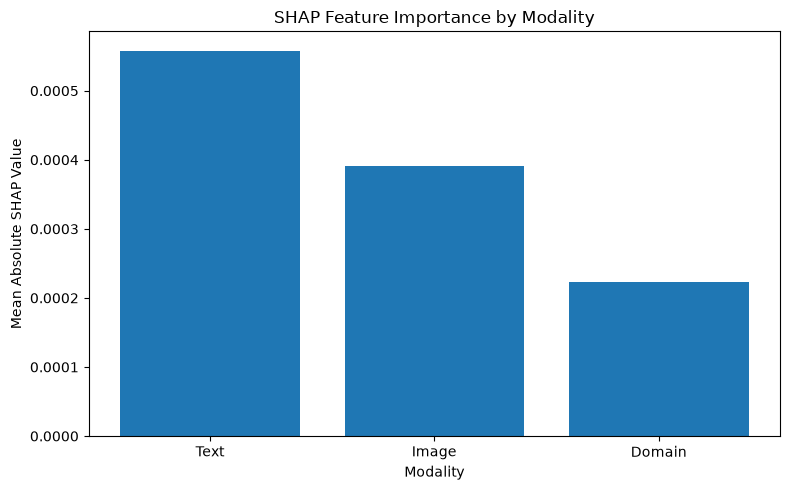

In [36]:
# now create visulization 

import matplotlib.pyplot as plt

modalities = ["Text", "Image", "Domain"]

importance_values = [
    text_importance,
    image_importance,
    domain_importance
]

plt.figure(figsize=(8, 5))

plt.bar(modalities, importance_values)

plt.title("SHAP Feature Importance by Modality")
plt.xlabel("Modality")
plt.ylabel("Mean Absolute SHAP Value")

plt.tight_layout()
plt.show()

In [37]:
# now save the Shap result 

import pandas as pd
import os

shap_results = pd.DataFrame({
    "Modality": ["Text", "Image", "Domain"],
    "Mean_SHAP_Importance": [
        text_importance,
        image_importance,
        domain_importance
    ]
})

os.makedirs("../results", exist_ok=True)

shap_results.to_csv(
    "../results/shap_modality_importance.csv",
    index=False
)

print("SHAP results saved successfully!")
display(shap_results)

SHAP results saved successfully!


,Modality,Mean_SHAP_Importance
0,Text,0.000558
1,Image,0.000391
2,Domain,0.000223


In [38]:
# now we will create the indivial prediction function 

def explain_news_prediction(sample_index):

    # Select test sample
    sample = X_test[sample_index:sample_index+1]

    # Predict class and probability
    prediction = final_model.predict(sample)[0]
    probabilities = final_model.predict_proba(sample)[0]

    # Calculate SHAP values
    shap_result = explainer.shap_values(
        sample,
        nsamples=100
    )

    # Extract Fake class SHAP values
    if isinstance(shap_result, list):
        fake_shap = np.array(shap_result[1])[0]
    else:
        fake_shap = np.array(shap_result)[0, :, 1]

    # Calculate modality contributions
    text_score = np.abs(fake_shap[:768]).mean()
    image_score = np.abs(fake_shap[768:1280]).mean()
    domain_score = np.abs(fake_shap[1280:1284]).mean()

    contributions = {
        "Text": text_score,
        "Image": image_score,
        "Domain": domain_score
    }

    print("=" * 45)
    print("FAKE NEWS DETECTION EXPLANATION")
    print("=" * 45)

    print("Prediction:",
          "Fake News" if prediction == 1 else "Real News")

    print(f"Real News Probability: {probabilities[0]*100:.2f}%")
    print(f"Fake News Probability: {probabilities[1]*100:.2f}%")

    print("\nModality Contributions:")

    for modality, score in contributions.items():
        print(f"{modality}: {score:.8f}")

    highest = max(contributions, key=contributions.get)

    print("\nHighest attribution magnitude:", highest)

    return contributions

In [39]:
explanation = explain_news_prediction(0)

  0%|          | 0/1 [00:00<?, ?it/s]

FAKE NEWS DETECTION EXPLANATION
Prediction: Fake News
Real News Probability: 0.04%
Fake News Probability: 99.96%

Modality Contributions:
Text: 0.00078922
Image: 0.00019769
Domain: 0.00000000

Highest attribution magnitude: Text


C:\Users\lenovo\anaconda3\envs\fake_news_pro\Lib\site-packages\shap\explainers\_kernel.py:765: UserWarning: Linear regression equation is singular, a least squares solutions is used instead.
To avoid this situation and get a regular matrix do one of the following:
1) turn up the number of samples,
2) turn up the L1 regularization with num_features(N) where N is less than the number of samples,
3) group features together to reduce the number of inputs that need to be explained.
  warnings.warn(


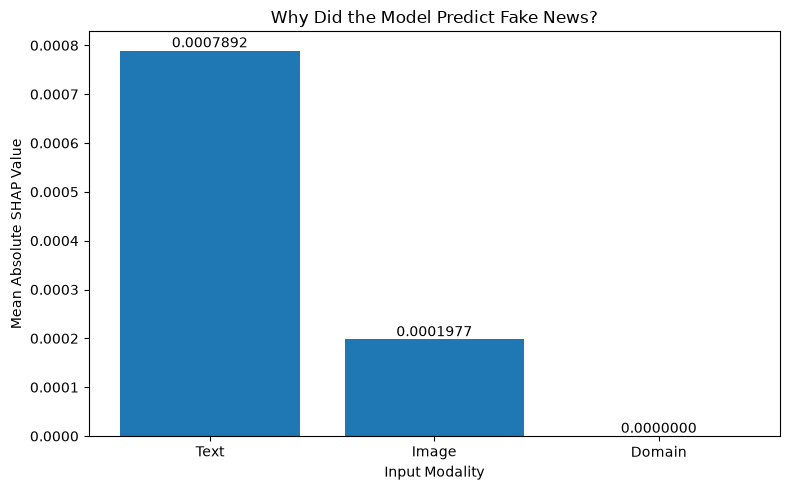

In [40]:
# now create the visuliazation 
import matplotlib.pyplot as plt

modalities = ["Text", "Image", "Domain"]

scores = [
    explanation["Text"],
    explanation["Image"],
    explanation["Domain"]
]

plt.figure(figsize=(8, 5))

bars = plt.bar(modalities, scores)

plt.title("Why Did the Model Predict Fake News?")
plt.xlabel("Input Modality")
plt.ylabel("Mean Absolute SHAP Value")

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{score:.7f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig("../results/individual_prediction_explanation.png")
plt.show()

In [41]:
# saved the graph

import os

print(
    "Explanation image saved:",
    os.path.exists(
        "../results/individual_prediction_explanation.png"
    )
)

Explanation image saved: True


In [42]:
# now we will calculate the positive and negative contributions

# Extract signed SHAP values for Fake News (class 1)
if isinstance(shap_values_10, list):
    fake_shap_10 = np.array(shap_values_10[1])
else:
    fake_shap_10 = np.array(shap_values_10)[:, :, 1]

# Analyze the first test sample
sample_shap = fake_shap_10[0]

# Sum signed contributions by modality
signed_contributions = {
    "Text": sample_shap[:768].sum(),
    "Image": sample_shap[768:1280].sum(),
    "Domain": sample_shap[1280:1284].sum()
}

print("DIRECTION OF MODEL CONTRIBUTIONS")
print("--------------------------------")

for modality, value in signed_contributions.items():

    direction = "Towards Fake" if value > 0 else "Towards Real"

    print(f"{modality}: {value:.8f} ({direction})")

DIRECTION OF MODEL CONTRIBUTIONS
--------------------------------
Text: 0.46634504 (Towards Fake)
Image: 0.01167397 (Towards Fake)
Domain: 0.00000000 (Towards Real)


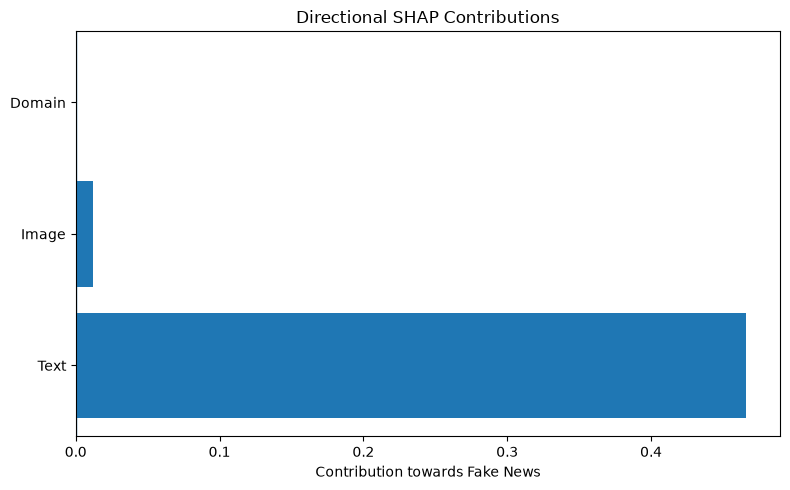

In [43]:
# Create directional SHAP visualization

import matplotlib.pyplot as plt

modalities = ["Text", "Image", "Domain"]

values = [
    signed_contributions["Text"],
    signed_contributions["Image"],
    signed_contributions["Domain"]
]

plt.figure(figsize=(8, 5))

plt.barh(modalities, values)

plt.axvline(0, linewidth=1)

plt.title("Directional SHAP Contributions")
plt.xlabel("Contribution towards Fake News")

plt.tight_layout()

plt.savefig(
    "../results/directional_shap_explanation.png"
)

plt.show()

In [44]:
# now save the directional result 

directional_df = pd.DataFrame({
    "Modality": modalities,
    "SHAP_Contribution": values
})

directional_df.to_csv(
    "../results/directional_shap_results.csv",
    index=False
)

print("Directional SHAP results saved successfully!")
display(directional_df)

Directional SHAP results saved successfully!


,Modality,SHAP_Contribution
0,Text,0.466345
1,Image,0.011674
2,Domain,0.000000
